## 1. Setup and Loading the Week 2 Cleaned Dataset
The cell below imports the libraries and loads the cleaned dataset. It looks for the file in the folder layout created by the Week 2 notebook (`Financial_Market_Analysis/cleaned_data/`), in the Google Colab `/content` folder, and in the current folder, so the notebook runs in either place without edits.

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Display settings (same float format used in Week 2)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Folder where all Week 3 figures are saved
VIS_DIR = "week_3_visualizations"
os.makedirs(VIS_DIR, exist_ok=True)

# Locate the Week 2 cleaned dataset
CANDIDATE_PATHS = [
    "Financial_Market_Analysis/cleaned_data/combined_cleaned_data.csv",
    "/content/Financial_Market_Analysis/cleaned_data/combined_cleaned_data.csv",
    "cleaned_data/combined_cleaned_data.csv",
    "combined_cleaned_data.csv",
    "/content/combined_cleaned_data.csv",
]
data_path = next((p for p in CANDIDATE_PATHS if Path(p).exists()), None)
if data_path is None:
    raise FileNotFoundError(
        "combined_cleaned_data.csv not found. Run the Week 2 notebook first, "
        "or place the file in this folder."
    )

df = pd.read_csv(data_path, parse_dates=["date"])
print("Loaded:", data_path)
print("Shape :", df.shape)

Loaded: Financial_Market_Analysis/cleaned_data/combined_cleaned_data.csv
Shape : (2220, 18)


In [ ]:
df.head()

,date,adj_close,close,dividends,high,low,open,stock_splits,volume,ticker,company,daily_return,return_outlier,volume_outlier,price_change,normalized_price,rolling_volatility,cumulative_return
0,2023-11-01,"1,219.96","1,354.15",0.00,"1,377.45","1,351.65","1,373.05",0.00,3090672,INFY.NS,Infosys,NaN,False,False,NaN,100.00,NaN,0.00
1,2023-11-02,"1,234.38","1,370.15",0.00,"1,376.30","1,361.65","1,370.00",0.00,3758060,INFY.NS,Infosys,1.18,False,False,14.41,101.18,NaN,1.18
2,2023-11-03,"1,251.40","1,389.05",0.00,"1,392.00","1,377.75","1,380.05",0.00,3349045,INFY.NS,Infosys,1.38,False,False,17.03,102.58,NaN,2.58
3,2023-11-06,"1,264.24","1,403.30",0.00,"1,407.25","1,390.80","1,393.90",0.00,2736381,INFY.NS,Infosys,1.03,False,False,12.84,103.63,NaN,3.63
4,2023-11-07,"1,265.14","1,404.30",0.00,"1,405.90","1,394.85","1,400.00",0.00,2272209,INFY.NS,Infosys,0.07,False,False,0.90,103.70,NaN,3.70


## 2. Dataset Overview
Before any analysis, the structure of the dataset is checked: number of rows and columns, column names, data types, date range, companies and the number of observations per company.

In [ ]:
print("Dataset shape (rows, columns):", df.shape)

print("\nCompanies and tickers:")
print(df[["company", "ticker"]].drop_duplicates().to_string(index=False))

print("\nDate range:", df["date"].min().date(), "to", df["date"].max().date())

print("\nObservations per company:")
print(df["company"].value_counts().to_string())

Dataset shape (rows, columns): (2220, 18)

Companies and tickers:
                  company      ticker
                  Infosys     INFY.NS
      Reliance Industries RELIANCE.NS
Tata Consultancy Services      TCS.NS

Date range: 2023-11-01 to 2026-10-30

Observations per company:
company
Infosys                      740
Reliance Industries          740
Tata Consultancy Services    740


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2220 entries, 0 to 2219
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                2220 non-null   datetime64[us]
 1   adj_close           2220 non-null   float64       
 2   close               2220 non-null   float64       
 3   dividends           2220 non-null   float64       
 4   high                2220 non-null   float64       
 5   low                 2220 non-null   float64       
 6   open                2220 non-null   float64       
 7   stock_splits        2220 non-null   float64       
 8   volume              2220 non-null   int64         
 9   ticker              2220 non-null   str           
 10  company             2220 non-null   str           
 11  daily_return        2217 non-null   float64       
 12  return_outlier      2220 non-null   bool          
 13  volume_outlier      2220 non-null   bool          
 14  pri

**Observations**
- The dataset has **2,220 rows × 18 columns**: 740 daily observations for each of the three companies.
- All three series cover the same period, **1 November 2023 to 30 October 2026**, so they are aligned date by date.
- `date` is a datetime column; prices, returns and volatility are floats; `volume` is an integer; `ticker` and `company` are text; `return_outlier` and `volume_outlier` are boolean flags.

## 3. Missing Values and Duplicate Checks

In [ ]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing %": (df.isnull().mean() * 100).round(2),
})
print("Columns with missing values:")
display(missing[missing["Missing Count"] > 0])
print("Total columns with no missing values:", int((missing["Missing Count"] == 0).sum()), "of", df.shape[1])

affected = ["daily_return", "price_change", "rolling_volatility"]
print("\nMissing values per company:")
display(df.groupby("company")[affected].apply(lambda g: g.isnull().sum()))

print("Exact duplicate rows            :", df.duplicated().sum())
print("Duplicate (ticker, date) records:", df.duplicated(subset=["ticker", "date"]).sum())

Columns with missing values:


,Missing Count,Missing %
daily_return,3,0.14
price_change,3,0.14
rolling_volatility,60,2.70


Total columns with no missing values: 15 of 18

Missing values per company:


,daily_return,price_change,rolling_volatility
company,,,
Infosys,1,1,20
Reliance Industries,1,1,20
Tata Consultancy Services,1,1,20


Exact duplicate rows            : 0
Duplicate (ticker, date) records: 0


**Why these values are missing (expected, not errors)**

- **`daily_return` – 3 missing (1 per company).** A return needs two consecutive prices, so the **first trading day of each company** has no return.
- **`price_change` – 3 missing (1 per company).** The first difference is likewise undefined on the first day.
- **`rolling_volatility` – 60 missing (20 per company).** Volatility is the standard deviation of **20 consecutive returns**. Because the first return is itself missing, the first valid volatility appears on the 21st row, leaving 20 empty values per company.

These rows are **kept, not filled or dropped**: inventing a return or volatility for dates with no history would create artificial values, and removing the rows would discard valid price, volume and return data. Pandas ignores missing values in `mean`, `median`, `std`, `corr` and plotting, so no special handling is needed.

All other columns are complete, and there are **no duplicate rows** and no duplicate (ticker, date) records.

## 4. Descriptive Statistics: Mean, Median, Mode and Standard Deviation
Summary statistics are calculated separately for each company for six numerical variables. Note that missing values (first-day returns, early rolling volatility) are automatically excluded by pandas.

In [ ]:
numeric_cols = [
    "adj_close", "volume", "daily_return",
    "price_change", "rolling_volatility", "cumulative_return",
]

def first_mode(x):
    m = x.mode()
    return m.iloc[0] if not m.empty else np.nan

tables = []
for col in numeric_cols:
    t = df.groupby("company")[col].agg(["mean", "median", first_mode, "std"])
    t.columns = ["Mean", "Median", "Mode", "Std Dev"]
    t.insert(0, "Variable", col)
    tables.append(t)

summary_stats = pd.concat(tables).reset_index().set_index(["Variable", "company"])
summary_stats

Mean        Median  \
Variable           company                                                 
adj_close          Infosys                        1,422.73      1,427.18   
                   Reliance Industries            1,364.79      1,377.51   
                   Tata Consultancy Services      3,177.71      3,243.94   
volume             Infosys                    8,809,672.60  7,335,856.50   
                   Reliance Industries       12,966,166.91 11,280,210.50   
                   Tata Consultancy Services  3,004,872.36  2,537,747.00   
daily_return       Infosys                            0.01         -0.07   
                   Reliance Industries                0.01          0.03   
                   Tata Consultancy Services         -0.01         -0.07   
price_change       Infosys                           -0.08         -0.86   
                   Reliance Industries                0.04          0.45   
                   Tata Consultancy Services         -0.71         -2.29   
rolling_volatility Infosys                            1.62          1.60   
                   Reliance Industries                1.30          1.23   
                   Tata Consultancy Services          1.45          1.39   
cumulative_return  Infosys                           16.62         16.99   
                   Reliance Industries               20.24         21.37   
                   Tata Consultancy Services          4.96          7.14   

                                                 Mode      Std Dev  
Variable           company                                          
adj_close          Infosys                   1,104.69       221.93  
                   Reliance Industries       1,267.26       105.90  
                   Tata Consultancy Services 3,299.90       595.66  
volume             Infosys                       0.00 6,108,774.11  
                   Reliance Industries           0.00 6,272,432.95  
                   Tata Consultancy Services     0.00 1,980,678.81  
daily_return       Infosys                       0.00         1.70  
                   Reliance Industries           0.00         1.34  
                   Tata Consultancy Services     0.00         1.53  
price_change       Infosys                       0.00        23.47  
                   Reliance Industries          -6.94        18.34  
                   Tata Consultancy Services     0.00        46.51  
rolling_volatility Infosys                       0.80         0.45  
                   Reliance Industries           0.56         0.38  
                   Tata Consultancy Services     0.65         0.46  
cumulative_return  Infosys                      -9.45        18.19  
                   Reliance Industries          11.65         9.33  
                   Tata Consultancy Services     8.99        19.67

**Notes on reading the table**

- **Price level differs greatly across companies** (mean `adj_close`: Infosys ≈ 1,422.73, Reliance ≈ 1,364.79, TCS ≈ 3,177.71), so raw prices are not directly comparable. Percentage returns and normalized prices are used for comparisons.
- **Mean daily returns are close to zero** for all three companies (0.01%, 0.01% and −0.01% at two decimals), and the medians are also close to zero. The **standard deviation** is the more informative measure: Infosys 1.70%, TCS 1.53%, Reliance 1.34%.
- **Volume:** the mean exceeds the median for every company, which indicates a right-skewed distribution in which a few very heavy trading days pull the mean upward.
- **`cumulative_return` mean** is the average of that series over time; it is **not** the return earned over the whole period (see Section 7.1 for end-of-period values).
- **The mode is of limited use for continuous financial variables.** Prices, returns and volatilities have many decimal places, so few values repeat; the "mode" is then simply the smallest value or one arbitrary repeated value. For example, the mode of `rolling_volatility` equals each company's minimum, and the mode of `volume` is 0 (explained in the next cell). The mode of `price_change` is similarly unreliable: for TCS several different values each occur exactly twice, so the "first mode" is just the smallest of a tie. Mean, median and standard deviation are the reliable summaries.

In [ ]:
zero_volume = df[df["volume"] == 0][["date", "company", "volume", "daily_return"]]
print("Days with zero volume, per company:")
print(zero_volume.groupby("company").size().to_string())
print("\nDates affected:", sorted(zero_volume["date"].dt.date.unique()))
print("Daily return on those days:", zero_volume["daily_return"].unique())

Days with zero volume, per company:
company
Infosys                      2
Reliance Industries          2
Tata Consultancy Services    2

Dates affected: [datetime.date(2025, 3, 18), datetime.date(2026, 1, 15)]
Daily return on those days: [0.]


**Observation:** all three companies report **zero volume on the same two dates (18 March 2025 and 15 January 2026)**, with an exactly zero daily return on those days. Because the dates coincide across all three tickers, they look like data-feed gaps rather than company-specific events, although the cause was not verified. These two days (2 of 740 observations per company) explain why the mode of volume is 0. They are **kept** to remain consistent with the Week 2 dataset; their effect on the mean volume is small (about 0.3%).

## 5. Analysis of Price, Trading Volume and Daily Returns
This section compares the companies on price level, trading activity, return behaviour and volatility.

In [ ]:
company_analysis = df.groupby("company").agg(
    Average_Price=("adj_close", "mean"),
    Median_Price=("adj_close", "median"),
    Average_Volume=("volume", "mean"),
    Median_Volume=("volume", "median"),
    Average_Return=("daily_return", "mean"),
    Minimum_Return=("daily_return", "min"),
    Maximum_Return=("daily_return", "max"),
    Return_Std_Dev=("daily_return", "std"),
    Average_Volatility=("rolling_volatility", "mean"),
    Minimum_Volatility=("rolling_volatility", "min"),
    Maximum_Volatility=("rolling_volatility", "max"),
).round(3)
company_analysis.T

company,Infosys,Reliance Industries,Tata Consultancy Services
Average_Price,"1,422.73","1,364.79","3,177.71"
Median_Price,"1,427.18","1,377.51","3,243.94"
Average_Volume,"8,809,672.60","12,966,166.91","3,004,872.36"
Median_Volume,"7,335,856.50","11,280,210.50","2,537,747.00"
Average_Return,0.01,0.01,-0.01
Minimum_Return,-7.26,-7.49,-8.39
Maximum_Return,7.93,7.02,6.79
Return_Std_Dev,1.70,1.34,1.53
Average_Volatility,1.62,1.30,1.45
Minimum_Volatility,0.80,0.56,0.65


In [ ]:
perf = df.sort_values("date").groupby("company").agg(
    Final_Normalized_Price=("normalized_price", "last"),
    Final_Cumulative_Return_pct=("cumulative_return", "last"),
    Peak_Normalized_Price=("normalized_price", "max"),
    Lowest_Normalized_Price=("normalized_price", "min"),
)
perf["Peak_Date"] = df.loc[df.groupby("company")["normalized_price"].idxmax()].set_index("company")["date"].dt.date
perf["Lowest_Date"] = df.loc[df.groupby("company")["normalized_price"].idxmin()].set_index("company")["date"].dt.date
perf

,Final_Normalized_Price,Final_Cumulative_Return_pct,Peak_Normalized_Price,Lowest_Normalized_Price,Peak_Date,Lowest_Date
company,,,,,,
Infosys,94.96,-5.04,152.34,78.96,2024-12-13,2026-07-01
Reliance Industries,102.63,2.63,139.64,100.00,2026-01-02,2023-11-01
Tata Consultancy Services,82.66,-17.34,139.00,64.78,2024-08-30,2026-07-01


**Observations**

- **Price:** TCS has by far the highest price level; Infosys and Reliance are similar (≈ INR 1,400).
- **Volume:** Reliance trades the most shares on average (≈ 12.97 million per day), Infosys ≈ 8.81 million, and TCS the fewest (≈ 3.00 million).
- **Returns and risk:** average daily returns are close to zero for all three, but risk differs. Infosys has the highest return standard deviation (1.70%) and the widest daily range (−7.26% to +7.93%); Reliance has the lowest (1.34%). Average 20-day volatility ranks the companies in the same order (1.62%, 1.45%, 1.30%).
- **End-of-period performance:** from a base of 100, the final normalized prices were ≈ 94.96 (Infosys), ≈ 102.63 (Reliance) and ≈ 82.66 (TCS), i.e. cumulative returns of ≈ −5.04%, +2.63% and −17.34%. These depend on the chosen start and end dates.

## 6. Distribution Analysis and Anomaly / Outlier Identification
### 6.1 Shape of the daily-return distributions
Skewness measures asymmetry and (excess) kurtosis measures tail heaviness; a normal distribution has skewness 0 and excess kurtosis 0.

In [10]:
shape = df.groupby("company")["daily_return"].agg(
    Skewness="skew",
    Excess_Kurtosis=lambda s: s.kurt(),
)
shape["Share_of_days_within_±2%"] = df.groupby("company")["daily_return"].apply(
    lambda s: ((s > -2) & (s < 2)).sum() / s.notna().sum() * 100
)
shape

,Skewness,Excess_Kurtosis,Share_of_days_within_±2%
company,,,
Infosys,0.19,2.83,81.33
Reliance Industries,0.12,3.09,88.36
Tata Consultancy Services,0.22,3.92,86.33


### 6.2 Outliers using the IQR rule
The Week 2 notebook flagged a value as an outlier when it lay more than 1.5 × IQR beyond the first or third quartile of that company's own distribution. The rule is **recalculated here** to confirm it matches the stored `return_outlier` and `volume_outlier` flags. Flagged observations are **retained**: large market moves are genuine features of financial data, not necessarily errors.

In [11]:
rows = []
for company, g in df.groupby("company"):
    for var, flag in [("daily_return", "return_outlier"), ("volume", "volume_outlier")]:
        vals = g[var].dropna()
        q1, q3 = vals.quantile(0.25), vals.quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        recalculated = int(((vals < lower) | (vals > upper)).sum())
        rows.append({
            "Company": company, "Variable": var,
            "Q1": q1, "Q3": q3, "Lower bound": lower, "Upper bound": upper,
            "Outliers (recalculated)": recalculated,
            "Outliers (Week 2 flag)": int(g[flag].sum()),
            "% of observations": round(recalculated / len(vals) * 100, 1),
        })
outlier_check = pd.DataFrame(rows)
outlier_check

,Company,Variable,Q1,Q3,Lower bound,Upper bound,Outliers (recalculated),Outliers (Week 2 flag),% of observations
0,Infosys,daily_return,-0.89,0.84,-3.48,3.43,45,45,6.10
1,Infosys,volume,"5,139,626.00","10,186,068.00","-2,430,037.00","17,755,731.00",49,49,6.60
2,Reliance Industries,daily_return,-0.81,0.72,-3.11,3.02,28,28,3.80
3,Reliance Industries,volume,"8,621,395.50","15,713,797.00","-2,017,206.75","26,352,399.25",31,31,4.20
4,Tata Consultancy Services,daily_return,-0.83,0.70,-3.12,3.00,38,38,5.10
5,Tata Consultancy Services,volume,"1,808,836.25","3,446,918.00","-648,286.38","5,904,040.62",43,43,5.80


In [ ]:
for company, g in df.groupby("company"):
    print(f"--- {company} ---")
    print("Largest gains:")
    print(g.nlargest(3, "daily_return")[["date", "daily_return"]].to_string(index=False))
    print("Largest falls:")
    print(g.nsmallest(3, "daily_return")[["date", "daily_return"]].to_string(index=False))
    print()

--- Infosys ---
Largest gains:
      date  daily_return
2024-01-12          7.93
2025-05-12          7.91
2026-06-02          5.68
Largest falls:
      date  daily_return
2026-02-04         -7.26
2026-04-24         -6.93
2026-06-19         -6.75

--- Reliance Industries ---
Largest gains:
      date  daily_return
2024-01-29          7.02
2024-06-03          5.59
2025-04-28          5.26
Largest falls:
      date  daily_return
2024-06-04         -7.49
2026-03-27         -4.60
2026-01-06         -4.47

--- Tata Consultancy Services ---
Largest gains:
      date  daily_return
2026-10-13          6.79
2024-07-12          6.63
2026-06-02          6.51
Largest falls:
      date  daily_return
2026-06-03         -8.39
2026-02-04         -7.01
2026-02-12         -5.49



**Observations**

- All three distributions are centred near zero with **mild positive skewness (0.12 to 0.22)** and **excess kurtosis of 2.83 to 3.92**, i.e. heavier tails than a normal distribution: moves of several percent occur more often than a normal model would imply.
- The recalculated IQR counts match the stored Week 2 flags: **45 (Infosys), 28 (Reliance) and 38 (TCS) return outliers**, which is 6.1%, 3.8% and 5.1% of returns. Volume outliers are 49, 31 and 43.
- Extreme days sometimes affect several companies at once. For example, on **4 February 2026** Infosys fell 7.26% and TCS fell 7.01%. Reliance's largest fall (−7.49%) was on **4 June 2024**, the day after a +5.59% gain.
- The dataset alone cannot explain *why* these days were extreme; that would require external information (company announcements, market news), which was not examined.

## 7. Visualizations
Seven figures are produced. Each is saved at 300 dpi to the `week_3_visualizations/` folder and also displayed in the notebook.

| # | Figure | File | Question addressed |
|---|---|---|---|
| 1 | Normalized price trends | `normalized_price_trends.png` | How did the stocks perform relative to each other? |
| 2 | Daily return distribution | `daily_return_distribution.png` | What are the shape and spread of daily returns? |
| 3 | Daily return boxplot | `daily_return_boxplot.png` | How do medians, spread and extreme days compare? |
| 4 | Return correlation heatmap | `return_correlation.png` | Which stocks move together? |
| 5 | Rolling volatility | `rolling_volatility.png` | Does risk change over time? |
| 6 | Return scatterplots | `return_scatterplots.png` | How strong are pairwise relationships? |
| 7 | Monthly average returns | `monthly_average_returns.png` | Are there month-level patterns? |

### 7.1 Normalized Stock Price Trends
Raw prices are not comparable (TCS trades at more than twice the price of the others), so each adjusted close is rebased to 100 on the first day. A line chart shows relative performance over time.

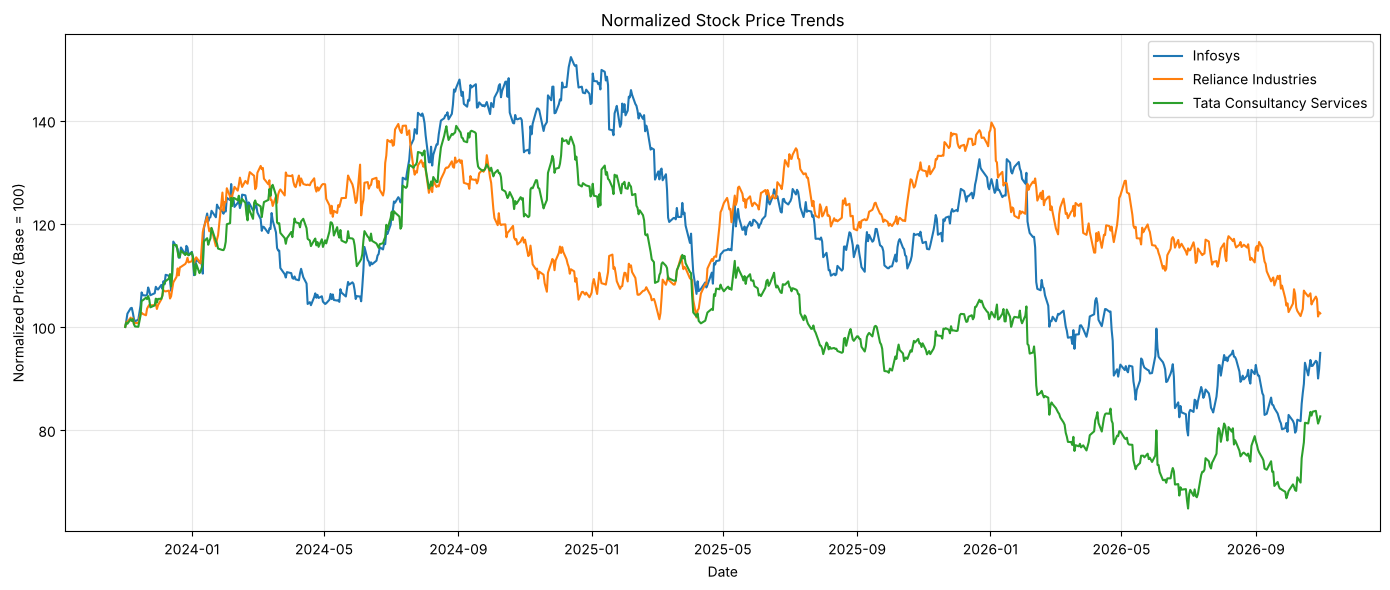

In [13]:
plt.figure(figsize=(14, 6))

for company in df["company"].unique():
    company_data = df[df["company"] == company]
    plt.plot(company_data["date"], company_data["normalized_price"], label=company)

plt.title("Normalized Stock Price Trends")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Base = 100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{VIS_DIR}/normalized_price_trends.png", dpi=300)
plt.show()

**Interpretation.** All three series rise together at first and then diverge. Infosys and TCS peak in 2024 (Infosys ≈ 152.3 on 13 Dec 2024; TCS ≈ 139.0 on 30 Aug 2024), decline afterwards, and both reach their lowest levels on 1 July 2026 (≈ 79.0 and ≈ 64.8). Reliance peaks later (≈ 139.6 on 2 Jan 2026) and never falls below its starting value of 100. By 30 October 2026 the normalized values were ≈ 94.96 (Infosys), ≈ 102.63 (Reliance) and ≈ 82.66 (TCS). This describes this specific window only; a different start date would change the comparison.

### 7.2 Daily Return Distribution
Histograms (30 bins) with a kernel density estimate show how often each range of daily returns occurs. Separate panels allow spread and tail behaviour to be compared with the standard deviations in Section 4.

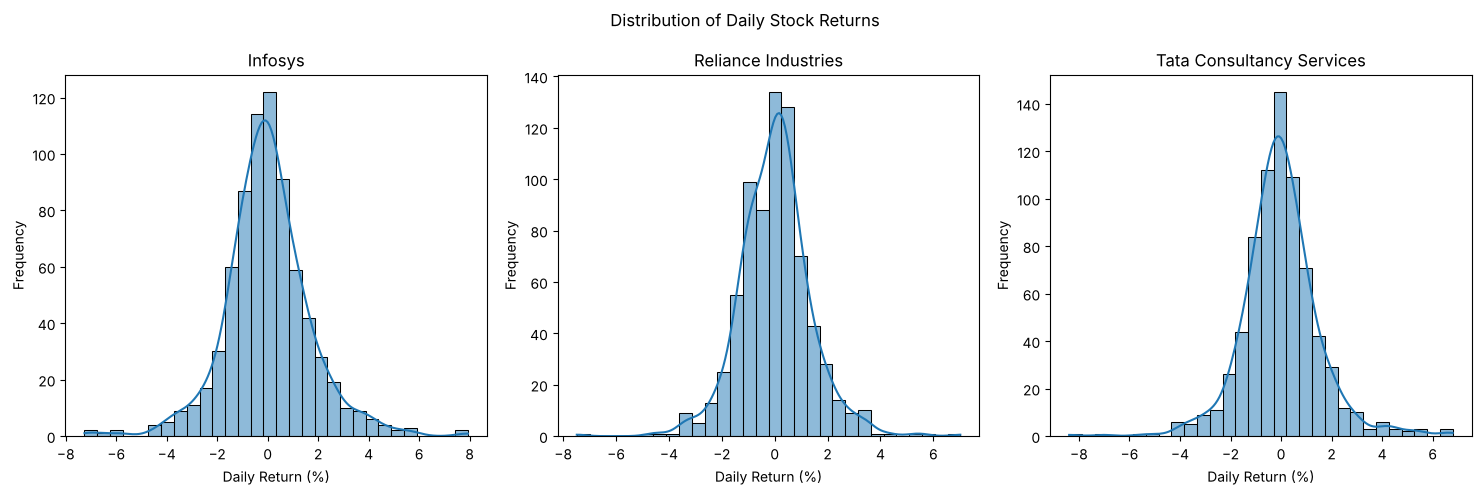

In [14]:
plt.figure(figsize=(15, 5))

for i, company in enumerate(df["company"].unique(), 1):
    plt.subplot(1, 3, i)
    sns.histplot(
        df[df["company"] == company]["daily_return"].dropna(),  # drop the first-day NaN
        bins=30,
        kde=True,
    )
    plt.title(company)
    plt.xlabel("Daily Return (%)")
    plt.ylabel("Frequency")

plt.suptitle("Distribution of Daily Stock Returns")
plt.tight_layout()
plt.savefig(f"{VIS_DIR}/daily_return_distribution.png", dpi=300)
plt.show()

**Interpretation.** Each distribution is a single, roughly symmetric peak centred near 0%, with thin tails reaching about −7% to −8% and +7% to +8%. Infosys has the widest central spread (std 1.70%) and Reliance the most concentrated (std 1.34%; 88.2% of days within ±2%, against 81.3% for Infosys and 86.2% for TCS). The heavy tails (excess kurtosis 2.83 to 3.92) mean that a risk estimate assuming normally distributed returns would understate how often large moves occur.

### 7.3 Daily Return Boxplot
A boxplot summarizes each distribution by its median, interquartile range and whiskers (1.5 × IQR), and plots observations beyond the whiskers individually, which makes the extreme days explicit.

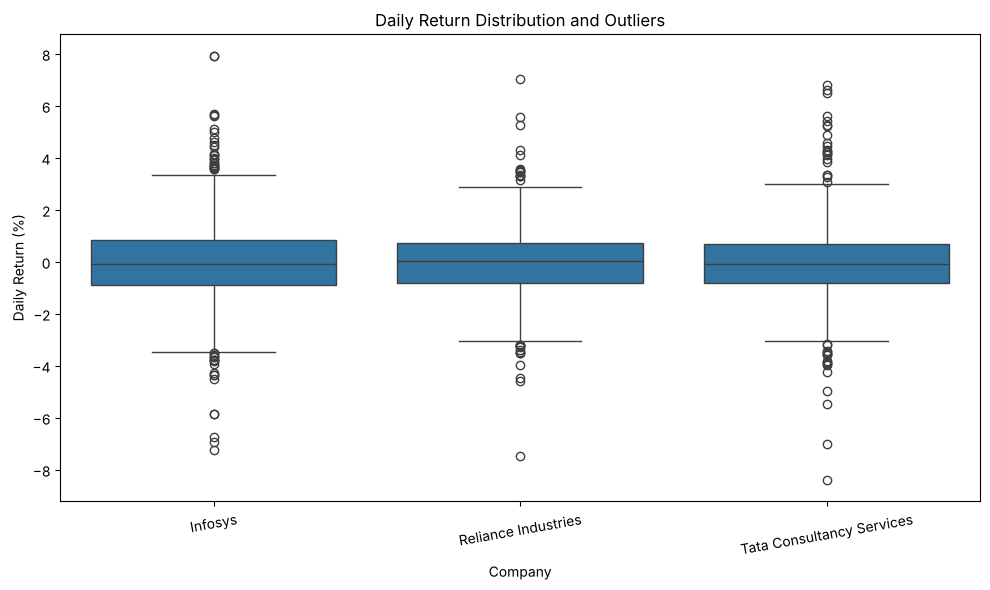

In [15]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="company", y="daily_return")

plt.title("Daily Return Distribution and Outliers")
plt.xlabel("Company")
plt.ylabel("Daily Return (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(f"{VIS_DIR}/daily_return_boxplot.png", dpi=300)
plt.show()

**Interpretation.** The middle 50% of returns are similar across the three stocks (medians −0.07%, 0.03% and −0.07%), but Infosys has the widest interquartile range (−0.89% to 0.84%) and the most outliers (45), while Reliance has the fewest (28). Outliers occur in both tails, so extreme moves are not confined to falls or gains. The most extreme single points are Reliance's ≈ −7.5% and TCS's ≈ −8.4%. Because the IQR rule is applied to heavy-tailed data, many points are flagged; they are unusually large moves, not errors.

### 7.4 Return Correlation Heatmap
A correlation heatmap condenses the pairwise relationships between the three return series into one grid. It is calculated on **returns, not prices**, because price levels trend and would give misleading correlations.

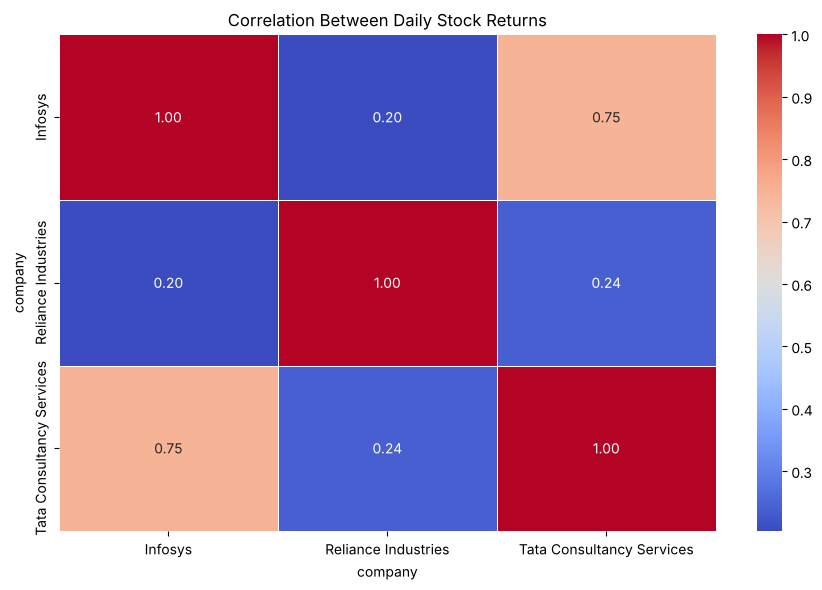

company                    Infosys  Reliance Industries  \
company                                                   
Infosys                       1.00                 0.20   
Reliance Industries           0.20                 1.00   
Tata Consultancy Services     0.75                 0.24   

company                    Tata Consultancy Services  
company                                               
Infosys                                         0.75  
Reliance Industries                             0.24  
Tata Consultancy Services                       1.00  


In [16]:
# One column of daily returns per company (rows aligned by date)
returns_pivot = df.pivot(index="date", columns="company", values="daily_return")

# Pearson correlation matrix of same-day returns
correlation_matrix = returns_pivot.corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
)
plt.title("Correlation Between Daily Stock Returns")
plt.tight_layout()
plt.savefig(f"{VIS_DIR}/return_correlation.png", dpi=300)
plt.show()

print(correlation_matrix.round(2))

**Interpretation.** Infosys and TCS have a strong positive correlation (**0.75**), whereas Reliance is only weakly correlated with Infosys (**0.20**) and with TCS (**0.24**). Infosys and TCS tend to move in the same direction on the same day. Infosys and TCS are both IT-services companies while Reliance is a diversified group, which is a plausible reason for the difference, but this is background knowledge and was not tested here. **Correlation measures co-movement only and does not prove that one stock causes another to move**; a common factor such as sector news or the overall market could drive both.

### 7.5 Rolling Volatility
A single standard deviation for the whole period hides the fact that risk changes over time. The 20-day rolling standard deviation of daily returns shows how volatility evolved. The first 20 values of each series are missing by construction (Section 3) and are simply not drawn.

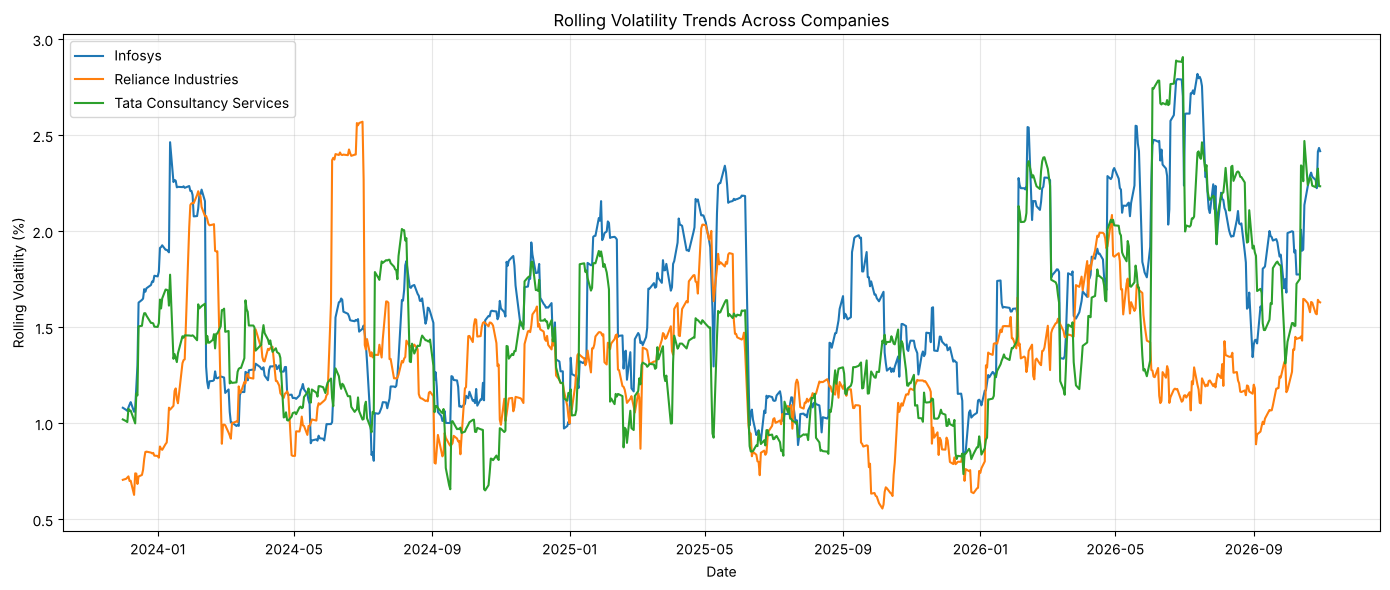

In [17]:
plt.figure(figsize=(14, 6))

for company in df["company"].unique():
    company_data = df[df["company"] == company]
    plt.plot(company_data["date"], company_data["rolling_volatility"], label=company)

plt.title("Rolling Volatility Trends Across Companies")
plt.xlabel("Date")
plt.ylabel("Rolling Volatility (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{VIS_DIR}/rolling_volatility.png", dpi=300)
plt.show()

**Interpretation.** Volatility is clearly **not constant**. It ranges from about 0.56% to 2.91% over the period (Infosys 0.80%–2.82%, Reliance 0.56%–2.57%, TCS 0.65%–2.91%), and the highest value is roughly 3.5 to 4.6 times the lowest for each company. Infosys and TCS reach their highest levels in mid-2026, while Reliance's highest spell was in mid-2024. Many sections move in abrupt steps: this is a feature of the 20-day window, where one very large return raises the measure and keeps it high until it leaves the window 20 days later. The Reliance plateau of about 2.4%–2.57% in mid-2024 is consistent with its +5.59% and −7.49% returns on 3 and 4 June 2024.

### 7.6 Return Scatterplots
The heatmap gives one number per pair; a scatter plot shows whether that number reflects a consistent relationship or is driven by a few points. Each point is one trading day and the line is a fitted linear regression. The pair with the highest correlation (Infosys vs TCS) and a low-correlation pair (Infosys vs Reliance) are shown.

Dates used: 739


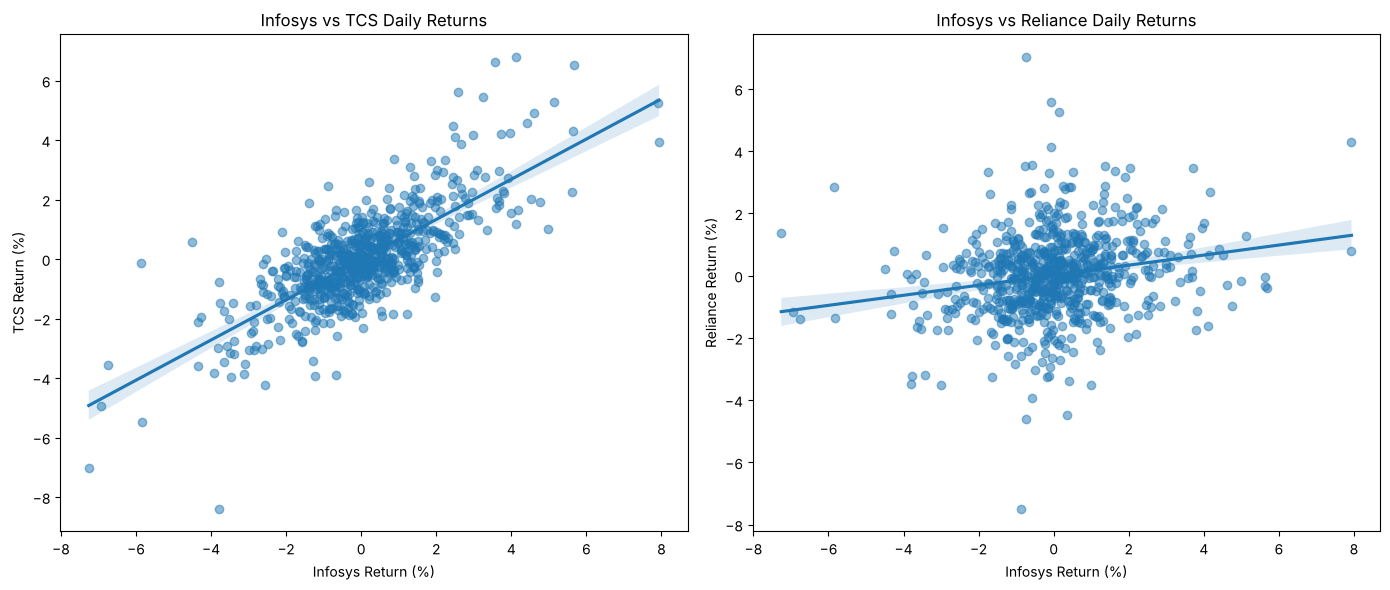

In [18]:
# Keep only dates on which all three companies have a return
returns_pairs = df.pivot(
    index="date", columns="company", values="daily_return"
).dropna()
print("Dates used:", len(returns_pairs))

# seed=42 fixes the bootstrap used for the confidence band, so the figure is reproducible

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Infosys vs TCS
sns.regplot(
    x=returns_pairs["Infosys"],
    y=returns_pairs["Tata Consultancy Services"],
    ax=axes[0],
    scatter_kws={"alpha": 0.5},
    seed=42,
)
axes[0].set_title("Infosys vs TCS Daily Returns")
axes[0].set_xlabel("Infosys Return (%)")
axes[0].set_ylabel("TCS Return (%)")

# Infosys vs Reliance
sns.regplot(
    x=returns_pairs["Infosys"],
    y=returns_pairs["Reliance Industries"],
    ax=axes[1],
    scatter_kws={"alpha": 0.5},
    seed=42,
)
axes[1].set_title("Infosys vs Reliance Daily Returns")
axes[1].set_xlabel("Infosys Return (%)")
axes[1].set_ylabel("Reliance Return (%)")

plt.tight_layout()
plt.savefig(f"{VIS_DIR}/return_scatterplots.png", dpi=300)
plt.show()

**Interpretation.** In the left panel the points form a tilted, elongated cloud around an upward-sloping line, so the strong Infosys–TCS correlation (0.75) is a consistent relationship across the range of returns, including the largest joint fall (≈ −7.3% Infosys, ≈ −7.0% TCS on 4 Feb 2026). In the right panel the cloud is broad and almost round and the fitted line is nearly flat, consistent with the weak correlation of 0.20: Infosys's return on a given day says little about Reliance's. Only two of the three pairs are plotted; the Reliance–TCS pair (0.24) appears in the heatmap only. This shows co-movement, not causation.

### 7.7 Monthly Average Daily Returns
Averaging daily returns within each calendar month removes day-to-day noise and shows longer-term patterns.

> **Important:** each value is the **average of the daily returns within a month**. It is **not a compounded monthly return** and must not be read as the % gain or loss from holding a stock for that month.

Months per company:
company
Infosys                      36
Reliance Industries          36
Tata Consultancy Services    36


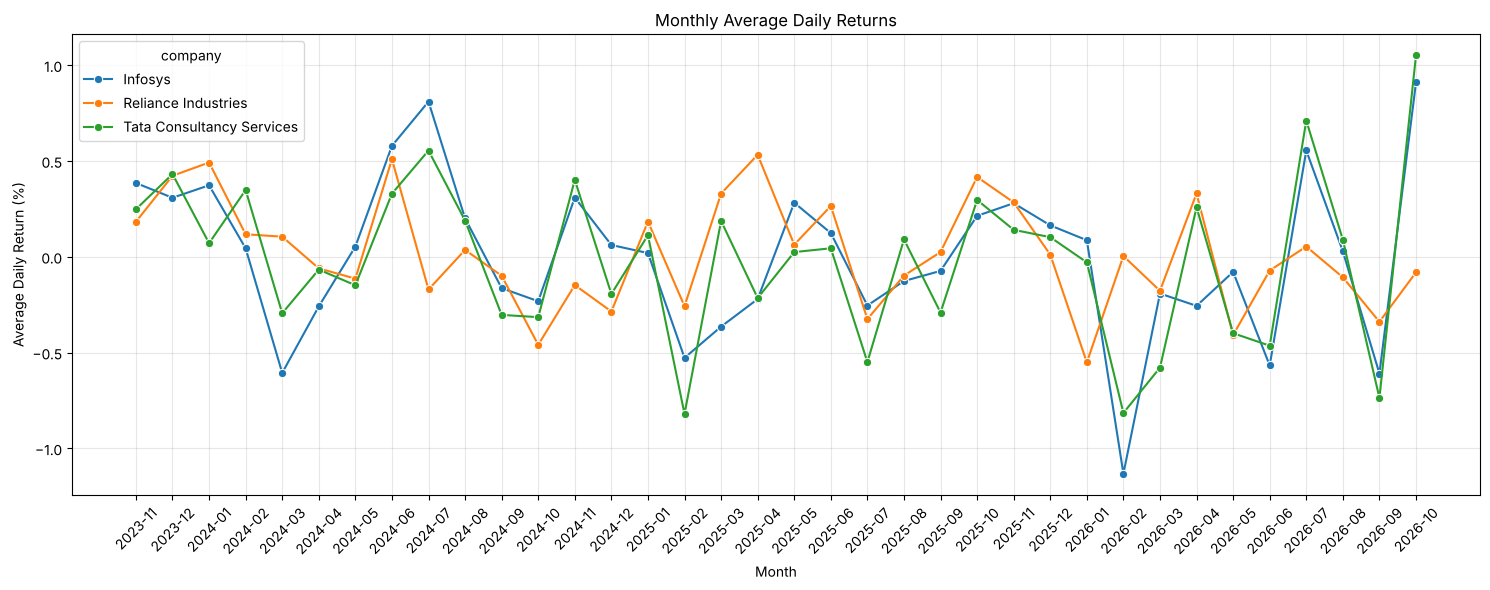

In [ ]:
# (a temporary month column is used so that df itself is left unchanged)
monthly_returns = (
    df.assign(year_month=df["date"].dt.to_period("M"))
      .groupby(["company", "year_month"])["daily_return"]
      .mean()
      .reset_index()
)
print("Months per company:")
print(monthly_returns.groupby("company").size().to_string())

# Convert monthly periods into strings for plotting
monthly_returns["year_month"] = monthly_returns["year_month"].astype(str)

plt.figure(figsize=(15, 6))
sns.lineplot(
    data=monthly_returns,
    x="year_month",
    y="daily_return",
    hue="company",
    marker="o",
)
plt.title("Monthly Average Daily Returns")
plt.xlabel("Month")
plt.ylabel("Average Daily Return (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{VIS_DIR}/monthly_average_returns.png", dpi=300)
plt.show()

In [ ]:
best = monthly_returns.loc[monthly_returns.groupby("company")["daily_return"].idxmax()]
worst = monthly_returns.loc[monthly_returns.groupby("company")["daily_return"].idxmin()]

monthly_extremes = best[["company", "year_month", "daily_return"]].rename(
    columns={"year_month": "Best_Month", "daily_return": "Best_Month_Avg_Daily_Return"}
).merge(
    worst[["company", "year_month", "daily_return"]].rename(
        columns={"year_month": "Worst_Month", "daily_return": "Worst_Month_Avg_Daily_Return"}
    ),
    on="company",
)
monthly_extremes.round(3)

,company,Best_Month,Best_Month_Avg_Daily_Return,Worst_Month,Worst_Month_Avg_Daily_Return
0,Infosys,2026-10,0.91,2026-02,-1.13
1,Reliance Industries,2025-04,0.53,2026-01,-0.55
2,Tata Consultancy Services,2026-10,1.05,2025-02,-0.82


**Interpretation.** Monthly averages swing between about −1.1% and +1.1% per day and change sign frequently. Infosys and TCS often move in the same direction in the same month and share the same best month (**October 2026**: +0.91% and +1.05%), while Reliance follows its own path in several periods (best April 2025, +0.53%; worst January 2026, −0.55%). The worst months are February 2026 for Infosys (−1.13%) and February 2025 for TCS (−0.82%).

An average daily return of +1.05% in October 2026 means the *average trading day* in that month was a gain of about one percent for TCS; it does **not** mean TCS gained 1.05% over the month. With only 36 months per company, recurring seasonal patterns cannot be claimed.

In [ ]:
expected_files = [
    "normalized_price_trends.png", "daily_return_distribution.png",
    "daily_return_boxplot.png", "return_correlation.png",
    "rolling_volatility.png", "return_scatterplots.png",
    "monthly_average_returns.png",
]
for f in expected_files:
    path = Path(VIS_DIR) / f
    status = f"saved ({path.stat().st_size / 1024:,.0f} KB)" if path.exists() else "MISSING"
    print(f"{f:<32} {status}")

normalized_price_trends.png      saved (568 KB)
daily_return_distribution.png    saved (288 KB)
daily_return_boxplot.png         saved (155 KB)
return_correlation.png           saved (156 KB)
rolling_volatility.png           saved (713 KB)
return_scatterplots.png          saved (792 KB)
monthly_average_returns.png      saved (646 KB)


## 8. Initial Hypotheses and Evidence Check
Four initial hypotheses are stated and compared with the calculated values. This is **descriptive EDA**: no formal statistical tests were run, so "supported" means *consistent with the pattern observed in this sample*.

| # | Hypothesis |
|---|---|
| H1 | Daily return variability differs among the three companies. |
| H2 | Companies in the same broad industry show stronger co-movement in daily returns. |
| H3 | Market volatility changes over time rather than remaining constant. |
| H4 | Higher average trading volume does not necessarily imply higher return volatility. |

In [22]:
# Evidence for each hypothesis, computed from the data
evidence = df.groupby("company").agg(
    Return_Std_Dev=("daily_return", "std"),                 # H1
    Min_Rolling_Vol=("rolling_volatility", "min"),          # H3
    Max_Rolling_Vol=("rolling_volatility", "max"),          # H3
    Average_Volume=("volume", "mean"),                      # H4
    Average_Rolling_Vol=("rolling_volatility", "mean"),     # H4
)
evidence["Max/Min Vol ratio"] = evidence["Max_Rolling_Vol"] / evidence["Min_Rolling_Vol"]
print("H1, H3, H4 evidence:")
display(evidence.round(2))

print("H2 evidence - correlations of daily returns:")
print(f"  Infosys  - TCS     : {correlation_matrix.loc['Infosys', 'Tata Consultancy Services']:.2f}")
print(f"  Infosys  - Reliance: {correlation_matrix.loc['Infosys', 'Reliance Industries']:.2f}")
print(f"  Reliance - TCS     : {correlation_matrix.loc['Reliance Industries', 'Tata Consultancy Services']:.2f}")

H1, H3, H4 evidence:


,Return_Std_Dev,Min_Rolling_Vol,Max_Rolling_Vol,Average_Volume,Average_Rolling_Vol,Max/Min Vol ratio
company,,,,,,
Infosys,1.70,0.80,2.82,"8,809,672.60",1.62,3.51
Reliance Industries,1.34,0.56,2.57,"12,966,166.91",1.30,4.62
Tata Consultancy Services,1.53,0.65,2.91,"3,004,872.36",1.45,4.47


H2 evidence - correlations of daily returns:
  Infosys  - TCS     : 0.75
  Infosys  - Reliance: 0.20
  Reliance - TCS     : 0.24


| # | Assessment | Evidence |
|---|---|---|
| H1 | **Supported descriptively.** Differences are visible; their statistical significance was not tested. | Return std: Infosys 1.70%, TCS 1.53%, Reliance 1.34%; outlier counts 45, 38, 28. |
| H2 | **Supported for these three companies.** Only one same-industry pair exists, and the industry grouping is external context. | Infosys–TCS 0.75 vs 0.20 (Infosys–Reliance) and 0.24 (Reliance–TCS). |
| H3 | **Supported.** Volatility is clearly time-varying in this sample. | Rolling volatility ranges 0.56%–2.91%; maximum is 3.5–4.6× the minimum. |
| H4 | **Consistent with the hypothesis in this three-company comparison**, but weak evidence (only three points; share counts and prices differ). | Reliance: highest volume (12.97m), lowest volatility; TCS: lowest volume (3.00m), middle volatility; Infosys: middle volume (8.81m), highest volatility. |

## 9. Summary of Key EDA Findings

1. **Data quality is high.** 2,220 rows, 18 columns, no duplicates, and 740 observations per company. The only missing values (3 daily returns, 3 price changes, 60 rolling-volatility values) are expected results of first-day and 20-day-window calculations.
2. **Average daily returns are near zero, but risk differs.** Mean daily returns are about 0.007%, 0.013% and −0.014% (Infosys, Reliance, TCS); return standard deviations are 1.70%, 1.34% and 1.53%.
3. **Returns have heavy tails.** Excess kurtosis of 2.83–3.92 and 111 flagged return outliers (45 + 28 + 38) show that large moves are common relative to a normal distribution. These observations were retained.
4. **Infosys and TCS move closely together** (correlation 0.75); pairs involving Reliance are only weakly correlated (0.20 and 0.24).
5. **Volatility changes over time**, ranging from 0.56% to 2.91%, with the highest readings for Infosys and TCS in mid-2026 and for Reliance in mid-2024.
6. **Performance diverged.** From a base of 100, the final values were ≈ 94.96 (Infosys), ≈ 102.63 (Reliance) and ≈ 82.66 (TCS).
7. **Monthly average daily returns** are volatile and change sign often (from +1.05% for TCS in October 2026 to −1.13% for Infosys in February 2026). These are averages of daily returns, **not compounded monthly returns**.
8. **Volume and volatility** do not move together in this three-company comparison (H4).

### Limitations
- Only three companies (two in the same sector) and about three years of data; conclusions cannot be generalized.
- The analysis is descriptive: no formal hypothesis tests or models were used.
- Correlation describes same-day co-movement and does not establish causation.
- Two dates with zero volume (all three companies) were kept and their cause was not verified.
- Data come from Yahoo Finance and were not cross-checked against another source.